##  An image segmentation example

In [ ]:
#Image segmentation in deep learning is about using a model to attribute a class to each pixel in an image
#thus segmenting the image into different zones(such as 'background', 'car', 'cat')

###There are two different flavors of image segmentation that you should know about:
* Semantic segmentation, where each pixel is independently classified into a semantic category, like “cat.” If there are two cats in the image, the corresponding pixels are all mapped to the same generic “cat” category

* Instance segmentation, which seeks not only to classify image pixels by category,
  but also to parse out individual object instances. In an image with two cats in it,
  instance segmentation would treat “cat 1” and “cat 2” as two separate classes of
  pixels

In this example, we’ll focus on semantic segmentation: we’ll be looking once again at
images of cats and dogs, and this time we’ll learn how to tell apart the main subject
and its background.

 We’ll work with the Oxford-IIIT Pets [dataset](www.robots.ox.ac.uk/~vgg/data/pets/), which contains 7,390 pictures of various breeds of cats and dogs, together with
foreground-background segmentation masks for each picture. A segmentation mask is
the image-segmentation equivalent of a label: it’s an image the same size as the input
image, with a single color channel where each integer value corresponds to the class
of the corresponding pixel in the input image. In our case, the pixels of our segmentation masks can take one of three integer values:

*  1 (foreground)
*  2 (background)
*  3 (contour)

In [ ]:
-##download and unzip the dataset
!wget http://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz #Download a file from a URL(Web Get)
!wget http://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz
!tar -xf images.tar.gz # tar >> work with archive files
!tar -xf annotations.tar.gz # -x >> extract, f >> specifies the file to extract

# .tar.gz
# .tar >> an archive that bundles multiple files/folders into one file. It does not compress them by itself.
# .gz >> Gzip compression, which compresses a file.

--2026-09-02 16:13:33--  http://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz
Resolving www.robots.ox.ac.uk (www.robots.ox.ac.uk)... 129.67.94.2
Connecting to www.robots.ox.ac.uk (www.robots.ox.ac.uk)|129.67.94.2|:80... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz [following]
--2026-09-02 16:13:34--  https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz
Connecting to www.robots.ox.ac.uk (www.robots.ox.ac.uk)|129.67.94.2|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://thor.robots.ox.ac.uk/pets/images.tar.gz [following]
--2026-09-02 16:13:34--  https://thor.robots.ox.ac.uk/pets/images.tar.gz
Resolving thor.robots.ox.ac.uk (thor.robots.ox.ac.uk)... 129.67.95.98
Connecting to thor.robots.ox.ac.uk (thor.robots.ox.ac.uk)|129.67.95.98|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 791918971 (755M) [app

In [ ]:
#The input pictures are stored as JPG files in the images/ folder (such as images/Abyssinian_1.jpg), and the corresponding segmentation mask is stored as a PNG file with
#the same name in the annotations/trimaps/ folder (such as annotations/trimaps/Abyssinian_1.png).

In [ ]:
import os

input_dir = "images/"
target_dir = "annotations/trimaps/"
input_img_paths = sorted(
    [os.path.join(input_dir, fname)
    for fname in os.listdir(input_dir)

    if fname.endswith(".jpg")]
)

In [ ]:
len(input_img_paths)

7390

In [ ]:
target_paths = sorted(
  [os.path.join(target_dir, fname)
  for fname in os.listdir(target_dir)
  if fname.endswith(".png") and not fname.startswith(".")])

len(target_paths)

7390

In [ ]:
#Now, what does one of these inputs and its mask look like?

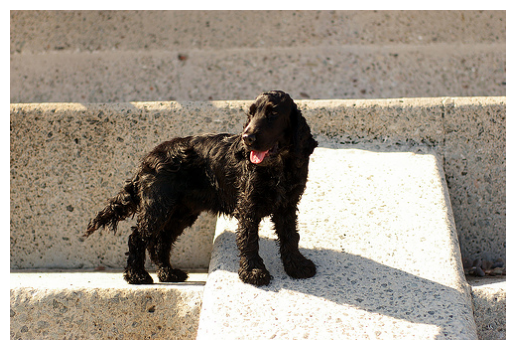

In [ ]:
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img, img_to_array
plt.axis("off")
plt.imshow(load_img(input_img_paths[9]))

In [ ]:
#corresponding target

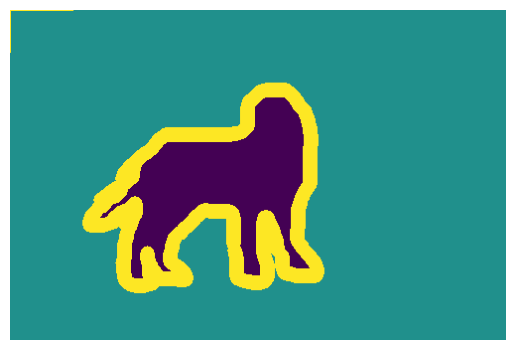

In [ ]:
def display_target(target_array):

  normalized_array = (target_array.astype("uint8") - 1) * 127
  plt.axis("off")
  plt.imshow(normalized_array[:, :, 0])
  #uint8 >> image/mask values into 8-bit unsigned integers.(0 to 255)
  # subtract -1 >> Segmentation mask (1 = background, 2 = pet) >> 1-1 =0 and 2-1 = 1
  # 127= gray, o= black, 255= white
img = img_to_array(load_img(target_paths[9], color_mode="grayscale"))
display_target(img)

It takes the image files and their segmentation-mask files, resizes them, converts them into arrays, and stores them in NumPy arrays ready for training.

In [ ]:
import numpy as np
import random

img_size = (200, 200)
num_imgs = len(input_img_paths)

random.Random(1337).shuffle(input_img_paths)#seed >>The order may be different every time you run the program without seed.
random.Random(1337).shuffle(target_paths)

def path_to_input_image(path):
  return img_to_array(load_img(path, target_size=img_size))

def path_to_target(path):
 img = img_to_array(
 load_img(path, target_size=img_size, color_mode="grayscale"))
 img = img.astype("uint8") - 1
 return img


input_imgs = np.zeros((num_imgs,) + img_size + (3,), dtype="float32")
targets = np.zeros((num_imgs,) + img_size + (1,), dtype="uint8")

for i in range(num_imgs):
  input_imgs[i] = path_to_input_image(input_img_paths[i])
  targets[i] = path_to_target(target_paths[i])

In [ ]:
num_val_samples = 1000
train_input_imgs = input_imgs[:-num_val_samples]
train_targets = targets[:-num_val_samples]
val_input_imgs = input_imgs[-num_val_samples:]
val_targets = targets[-num_val_samples:]

In [ ]:
#Now it’s time to define our model:

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

def get_model(img_size, num_classes):
  inputs = keras.Input(shape= img_size + (3,))

  x = layers.Rescaling(1./255)(inputs)

  x = layers.Conv2D(64, 3, strides=2, activation='relu', padding = 'same')(x)

  x = layers.Conv2D(64, 3,  activation='relu', padding = 'same')(x)

  x = layers.Conv2D(128, 3, strides=2, activation='relu', padding = 'same')(x)

  x = layers.Conv2D(128, 3,  activation='relu', padding = 'same')(x)

  x = layers.Conv2D(256, 3, strides=2, activation='relu', padding = 'same')(x)

  x = layers.Conv2D(256, 3, activation='relu', padding = 'same')(x)



  x = layers.Conv2DTranspose(256, 3, activation='relu', padding='same')(x)

  x = layers.Conv2DTranspose(256, 3, strides=2 , activation='relu', padding = 'same')(x)

  x = layers.Conv2DTranspose(128, 3, activation= 'relu', padding = 'same')(x)

  x = layers.Conv2DTranspose(128, 3, activation= 'relu', padding = 'same' , strides = 2)(x)

  x = layers.Conv2DTranspose(64, 3, activation = 'relu', padding = 'same')(x)

  x = layers.Conv2DTranspose(64, 3, activation= 'relu', padding='same', strides = 2)(x)

  outputs = layers.Conv2D(num_classes, 3, activation="softmax", padding = "same")(x)

  model = keras.Model(inputs, outputs)

  return model

In [ ]:
model = get_model(img_size, 3)

In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 100, 100, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 100, 100, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 50, 50, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 50, 50, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 25, 25, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 25, 25, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 25, 25, 256)    │       590,080 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 50, 50, 256)    │       590,080 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 50, 50, 128)    │       295,040 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 100, 100, 128)  │       147,584 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_4              │ (None, 100, 100, 64)   │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_5              │ (None, 200, 200, 64)   │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 200, 200, 3)    │         1,731 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,880,643 (10.99 MB)

 Trainable params: 2,880,643 (10.99 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
##let's compile and train the model now

model.compile(loss='sparse_categorical_crossentropy',
              optimizer = 'rmsprop')

In [ ]:
callbacks = [
 keras.callbacks.ModelCheckpoint("oxford_segmentation.keras",
 save_best_only=True)
]

In [ ]:
history = model.fit(train_input_imgs, train_targets,
  epochs=50,
  callbacks=callbacks,
  batch_size=64,
  validation_data=(val_input_imgs, val_targets))

Epoch 1/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 202s 2s/step - loss: 0.9483 - val_loss: 0.9843
Epoch 2/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 66s 643ms/step - loss: 0.9011 - val_loss: 0.8258
Epoch 3/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 62s 621ms/step - loss: 0.8409 - val_loss: 0.8271
Epoch 4/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 62s 624ms/step - loss: 0.8047 - val_loss: 0.7796
Epoch 5/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 62s 625ms/step - loss: 0.7815 - val_loss: 0.7360
Epoch 6/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 63s 628ms/step - loss: 0.7638 - val_loss: 0.7471
Epoch 7/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 63s 627ms/step - loss: 0.7528 - val_loss: 0.7328
Epoch 8/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 63s 630ms/step - loss: 0.7410 - val_loss: 0.7062
Epoch 9/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 62s 624ms/step - loss: 0.7233 - val_loss: 0.7285
Epoch 10/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 63s 627ms/step - loss: 0.7035 - val_loss: 0.6537
Epoch 11/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 63s 632ms/step - loss: 0.6714 - val_loss: 0.8521
Epoch 12/50
100/100 ━

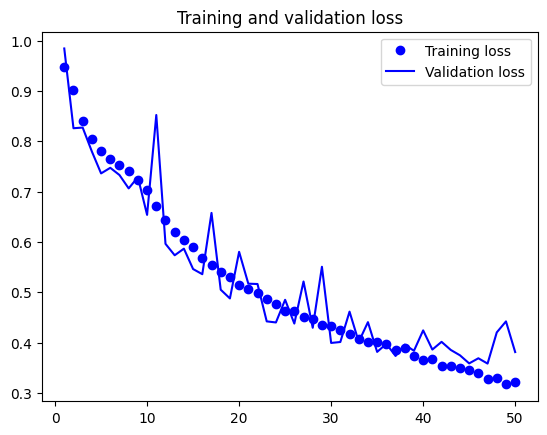

In [ ]:
epochs = range(1, len(history.history["loss"]) + 1)
loss = history.history["loss"]
val_loss = history.history["val_loss"]
plt.figure()
plt.plot(epochs, loss, "bo", label="Training loss")
plt.plot(epochs, val_loss, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.legend()


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


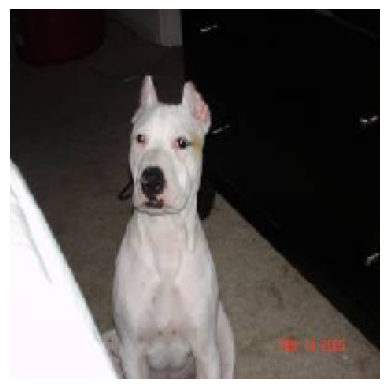

In [ ]:
from tensorflow.keras.utils import array_to_img
model = keras.models.load_model("oxford_segmentation.keras")

i = 4
test_image = val_input_imgs[i]
plt.axis("off")
plt.imshow(array_to_img(test_image))
mask = model.predict(np.expand_dims(test_image, 0))[0]

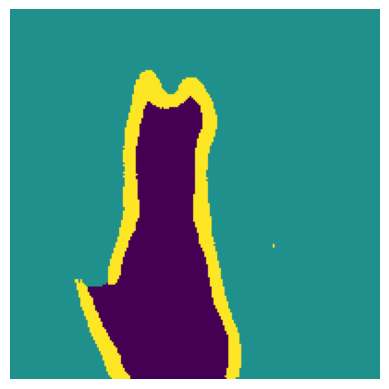

In [ ]:
def display_mask(pred):
 mask = np.argmax(pred, axis=-1)
 mask *= 127
 plt.axis("off")
 plt.imshow(mask)
display_mask(mask)